# Convolutional Neural Network (CNN) Example: Crack Detection in Inspection Images

**Background** <br>
Bridge and pavement inspections are being automated: send a drone (or a student with a phone), and let a CNN find the cracks. Why not MLP? An image has thousands of pixels. A fully connected layer would need a separate weight for every pixel position, and a crack shifted one pixel would confuse it. A convolution slides one small kernel everywhere. The same "crack detector" works at any location.

Real cracks are harder than you might expect: they vary in **position, width, direction, and contrast**, and intact surfaces contain dark spots and shadows that mimic cracks.

**Dataset** <br> 
400 photographs of concrete surfaces in campus buildings (METU, Ankara): 
- 200 with visible cracks
- 200 intact
from the public *Concrete Crack Images for Classification* dataset (Özgenel & Gönenç, 2018). Originals are 227×227 color JPGs. we downsample to 64×64 grayscale to keep training fast.

Özgenel, Ç.F. & Gönenç Sorguç, A. (2018), *Performance comparison of pretrained convolutional neural networks on crack detection in buildings*, ISARC 2018. Original dataset on Mendeley Data (`Concrete Crack Images for Classification`).

## The training loop

A training loop usually goes through the following five steps:

```python
optimizer.zero_grad()       # 1. forget the gradients from the previous step
y_hat  = model(x)           # 2. forward pass: make a prediction
loss   = loss_fn(y_hat, y)  # 3. measure how wrong we are
loss.backward()             # 4. backpropagation: compute gradients
optimizer.step()            # 5. update the weights a little
```

Only three things change between architectures: 
- the data
- the model (`nn.Module`) 
- the loss function

## CNN Model

In [1]:
import torch                        # PyTorch: tensors + autograd
import torch.nn as nn               # neural-network building blocks (layers, losses)
from torch.utils.data import TensorDataset, DataLoader   # pairs samples, yields mini-batches
from torchvision.datasets import ImageFolder   # reads "folder-per-class" image data
from torchvision import transforms  # image preprocessing pipeline
import matplotlib.pyplot as plt

torch.manual_seed(355)              # fix the RNG -> reproducible results
print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.1


### 1. Load the images

The photos are in `Data/ConcreteCrack/crack/` (crack present) and `Data/ConcreteCrack/intact/` (no crack). 

`torchvision.datasets.ImageFolder` reads such a folder layout in two lines: it finds the images, and it **infers the class label from the subfolder name**. 

We pass a `transform` that converts each photo to grayscale, resizes it to 64×64, and scales pixels to [0, 1].

In [2]:
# transforms.Compose chains preprocessing steps, applied to EVERY image
tfm = transforms.Compose([
    transforms.Grayscale(),               # 3 color channels -> 1 gray channel
    transforms.Resize((64, 64)),          # 227x227 -> 64x64 (fast training)
    transforms.ToTensor(),                # PIL image -> float tensor, pixels 0-255 -> [0,1]
])                                        # tensor shape (1, 64, 64) = (channel, height, width)

# Scans the folder. Subfolder names (crack/intact) become the class labels
dataset = ImageFolder("Data/ConcreteCrack", transform=tfm)
print(dataset.class_to_idx, "|", len(dataset), "images")   # the class label -> integer mapping

# collect all images into ONE tensor: (400, 1, 64, 64) = (N, C, H, W), the standard batch layout
X = torch.stack([img for img, _ in dataset])
y_raw = torch.tensor([label for _, label in dataset])       # integer labels 0/1
y = (y_raw == dataset.class_to_idx["crack"]).float().unsqueeze(1)  # 1 = crack
print("images:", X.shape, " labels:", y.shape)              # unsqueeze: (400,) -> (400,1) to match model output

{'crack': 0, 'intact': 1} | 400 images
images: torch.Size([400, 1, 64, 64])  labels: torch.Size([400, 1])


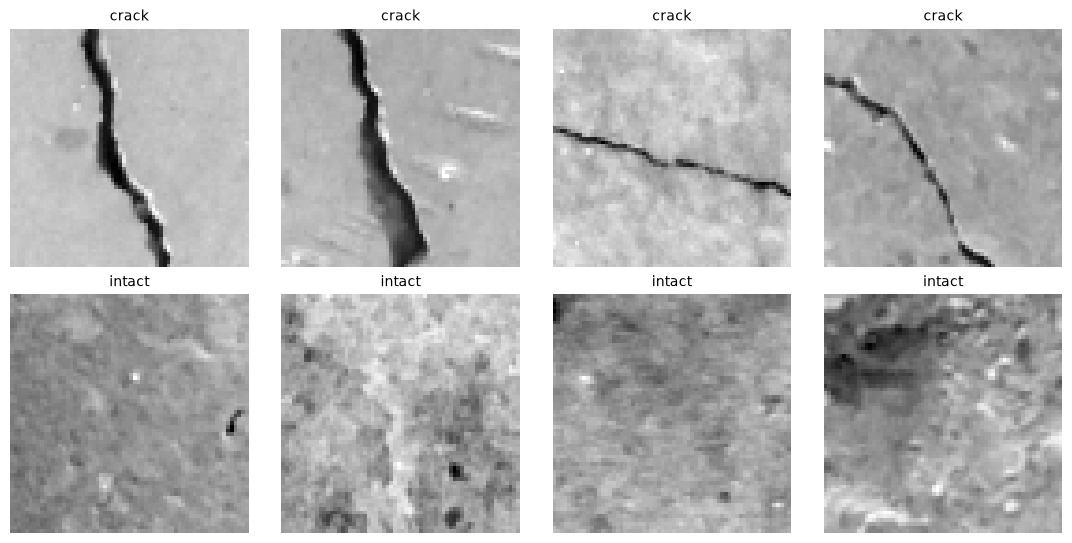

In [3]:
# look at a few real examples (stack order: crack 0-199, then intact 200-399)
# X[idx][0]: pick image idx, then take channel 0 -> the (64, 64) 2-D array imshow needs
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, idx in zip(axes.flat, [0, 1, 2, 3, 200, 210, 220, 230]):
    ax.imshow(X[idx][0], cmap="gray")
    ax.set_title("crack" if y[idx] == 1 else "intact", fontsize=10)
    ax.axis("off")
plt.tight_layout() 
plt.show()

### 2. Build the CNN model

Read the `features` block as a pipeline of pattern detectors:
- `Conv2d(1, 8, 5)`: eight 5×5 filters scan the image -> 8 "feature maps" (edges, dark lines…)
- `MaxPool2d(2)`: keep only the strongest response in each 2×2 patch → smaller, position-tolerant
- second conv layer builds combinations of the first (e.g. "long thin dark region" = crack)
- `Flatten` + `Linear`: vote on crack vs. intact

The final `nn.Sigmoid()` squashes the raw score into a **probability in (0, 1)** — `model(x)` directly means p(crack). Because the model outputs probabilities, the matching loss is `nn.BCELoss` (binary cross-entropy). Watch out: never pair a sigmoid output with `BCEWithLogitsLoss` — the sigmoid would be applied twice.

In [4]:
class DamageNet(nn.Module):          # every PyTorch model subclasses nn.Module
    def __init__(self):              # constructor: CREATE the layers here
        super().__init__()           # required: initialize the base class
        self.features = nn.Sequential(     # runs layers in order, like a pipeline
            nn.Conv2d(1, 8, kernel_size=5), nn.ReLU(),   # 8 learnable 5x5 kernels -> 8 feature maps; 64 -> 60
            nn.MaxPool2d(2),                    # keep max of each 2x2 block; 60 -> 30
            nn.Conv2d(8, 16, kernel_size=5), nn.ReLU(),  # 16 more 5x5 kernels 30 -> 26
            nn.MaxPool2d(2),                    # 26 -> 13
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                       # 16x13x13 volume -> vector of 2704
            nn.Linear(16 * 13 * 13, 32), nn.ReLU(),      # fully connected: 2704 -> 32
            nn.Linear(32, 1),                   # final layer -> 1 raw score per image
            nn.Sigmoid(),                       # squashes the score -> probability in (0, 1)
        )
    def forward(self, x):
        x = self.features(x)     # run the convolutions/pooling, get feature maps
        x = self.classifier(x)   # flatten + fully connected layers
        return x                 # p(crack), a probability in (0, 1)


model = DamageNet()                  # build the network (weights start random)
loss_fn   = nn.BCELoss()             # binary cross-entropy; expects probabilities in (0, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # updates all weights; lr = step size

### 3. Train with mini-batches

`TensorDataset` pairs each image with its label; the `DataLoader` then does the rest of the bookkeeping for us — **shuffling** the training set every epoch and **slicing it into mini-batches of 32**, which it yields one at a time as `(xb, yb)`. Inside the batch loop you still write the universal five-line training loop yourself. Real photos are harder than synthetic patterns — watch the accuracy climb over the epochs rather than jump.

In [5]:
# shuffle data
perm = torch.randperm(len(X))                 # random permutation of indices 0..399
X, y = X[perm], y[perm]                       # shuffle! folder order groups all cracks first

# train-test split
split = int(0.8 * len(X))                       # boundary for the 80/20 split
X_train, X_test, y_train, y_test = X[:split], X[split:], y[:split], y[split:]

# training dataset and the loader
train_ds = TensorDataset(X_train, y_train)      # pairs each image with its label
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)   # yields shuffled (xb, yb) batches of 32

# training
for epoch in range(15):                         # 1 epoch = one full pass over the training data
    model.train()                               # training mode (affects layers like dropout)
    total = 0.0
    for xb, yb in train_loader:                 # DataLoader shuffles + slices mini-batches for us
        optimizer.zero_grad()                   # gradients accumulate -> erase the previous step's
        out = model(xb)                         # forward pass: predictions for the batch
        loss = loss_fn(out, yb)                 # scalar: how wrong the batch is
        loss.backward()                         # backprop: dLoss/dWeight for EVERY weight (autograd)
        optimizer.step()                        # update all weights a small step downhill
        total += loss.item() * len(xb)          # .item() -> Python float; x batch size = fair average
    
    model.eval()                                # evaluation mode
    with torch.no_grad():                       # no gradients needed for testing (faster)
        acc = ((model(X_test) > 0.5).float() == y_test).float().mean()  # p>0.5 <=> "crack"; mean = accuracy
    
    print(f"epoch {epoch+1:2d} | train loss {total/len(train_ds):.4f} | test acc {acc:.1%}")

epoch  1 | train loss 0.6882 | test acc 76.2%
epoch  2 | train loss 0.6561 | test acc 71.2%
epoch  3 | train loss 0.5853 | test acc 95.0%
epoch  4 | train loss 0.4679 | test acc 91.3%
epoch  5 | train loss 0.4201 | test acc 95.0%
epoch  6 | train loss 0.3408 | test acc 98.8%
epoch  7 | train loss 0.2592 | test acc 97.5%
epoch  8 | train loss 0.2416 | test acc 93.8%
epoch  9 | train loss 0.2540 | test acc 98.8%
epoch 10 | train loss 0.2031 | test acc 100.0%
epoch 11 | train loss 0.1770 | test acc 97.5%
epoch 12 | train loss 0.1461 | test acc 100.0%
epoch 13 | train loss 0.1298 | test acc 100.0%
epoch 14 | train loss 0.1248 | test acc 100.0%
epoch 15 | train loss 0.1188 | test acc 100.0%


### 4. Test model - Look at the model's verdicts on unseen inspection images

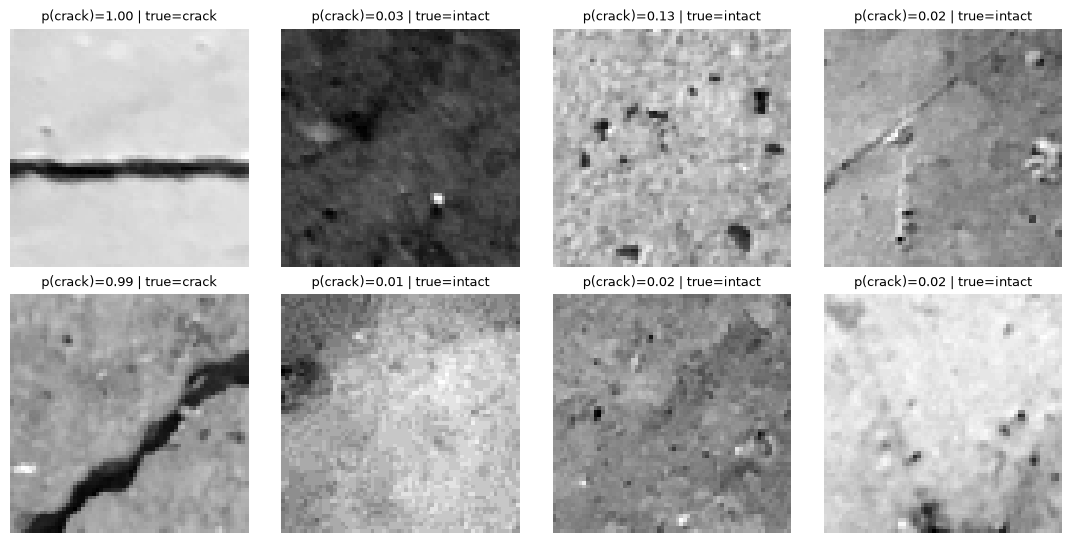

In [6]:
model.eval()                          # inference mode
with torch.no_grad():                 # no gradients during testing
    scores = model(X_test).squeeze()  # one p(crack) per test image; (400,1) -> (400,)

fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for k, ax in enumerate(axes.flat):
    p = scores[k].item()                        # model output is already a probability
    ax.imshow(X_test[k][0], cmap="gray")        # k-th TEST image, channel 0
    ax.set_title(f"p(crack)={p:.2f} | true={'crack' if y_test[k]==1 else 'intact'}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Check** <br>
Look at the misclassified test photos (if any). Are the errors plausible? Dark stains that look like cracks, hairline cracks that are barely visible? Real-data errors are worth inspecting, not just counting.

**Exercises**
1. Train on the full 227×227 color images instead of 64×64 grayscale. Is the accuracy worth the extra runtime?
2. Show the model a photo it gets wrong with `p(crack) ≈ 0.5`. What property of that image makes it ambiguous?
3. Inspect the first conv layer's filters (`model.features[0].weight`) with `plt.imshow`. What local patterns did it learn?